# 📘 통계 7장 실습: 상관과 회귀 (펭귄 데이터)

> 공부용 노트 · 발표용 · 복습용으로 함께 쓸 수 있게 정리했습니다.
> 각 문제는 **📖 상황 → 🧩 개념 → 💻 코드 → 📝 해설 → 🧠 데이터 읽는 법** 순서입니다.

## 📚 목차
- [⚙️ 환경 준비](#환경-준비)
- [핵심 용어 사전](#핵심-용어-사전) (먼저 한 번 읽고 시작)
- [문제 1. 부리는 길수록 두꺼울까? (산점도·상관, 집단 나누기)](#문제-1)
- [문제 2. 날개가 길면 몸무게도 무거울까? (정규성·피어슨·스피어만)](#문제-2)
- [문제 3. 그 관계를 하나의 식으로 (단순회귀)](#문제-3)
- [문제 4. 이 기울기, 우연이 아닐까? (회귀계수 검정)](#문제-4)
- [문제 5. 이 모형, 믿고 보고해도 될까? (R²·잔차·등분산)](#문제-5)
- [마지막: 데이터를 읽는 순서 한눈에 보기](#데이터를-읽는-순서)

---
<a id="환경-준비"></a>
## ⚙️ 환경 준비
라이브러리를 불러오고 한글 폰트를 설정합니다. 노트북을 처음 열면 이 셀부터 실행하세요.
(코랩을 쓴다면 나눔 폰트 설치가 먼저 필요합니다. 원본 교안의 1단계 설치 셀을 참고하세요.)

In [2]:
# ⚙️ 환경 준비: 라이브러리 불러오기 + 한글 폰트 설정
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf                 # 'y ~ x' 형태로 회귀식 쓰기
from statsmodels.stats.diagnostic import het_breuschpagan  # 등분산 검정(Breusch-Pagan)
import warnings
warnings.filterwarnings("ignore")                     # 불필요한 경고 숨김

# 스타일을 먼저 적용한 뒤 한글 폰트를 지정해야 글꼴이 유지됩니다.
sns.set_style("whitegrid")
system = platform.system()
if system == "Darwin":            # 맥
    plt.rcParams["font.family"] = "AppleGothic"
elif system == "Windows":         # 윈도우
    plt.rcParams["font.family"] = "Malgun Gothic"
else:                             # 코랩·리눅스 (나눔 폰트 설치 필요)
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False   # 음수 기호 깨짐 방지
plt.rcParams["figure.figsize"] = (8, 5)

print("준비 완료!")

준비 완료!


---
<a id="핵심-용어-사전"></a>
## 📖 핵심 용어 사전 (이 노트북에서 계속 나옵니다)

| 용어 | 한 줄 뜻 | 예 |
|---|---|---|
| **상관계수 r** | 두 변수가 같이 움직이는 방향과 강도를 −1~+1로 나타낸 값 | r = +0.87: 날개가 길수록 몸무게도 무거운 경향이 강함 |
| **산점도** | 점 하나 = 개체 하나, 두 변수의 관계를 그린 그림 | 펭귄 한 마리를 (부리 길이, 부리 두께) 좌표에 찍기 |
| **회귀식** | 원인 변수 x로 결과 변수 y를 예측하는 직선 y = a + bx | 몸무게 = a + b × 날개 길이 |
| **절편 a** | x가 0일 때의 예측값 | 우리 데이터 범위 밖의 값이라 해석에 주의 |
| **기울기 b** | x가 1 늘 때 y가 평균적으로 변하는 양 | b = 49.7 → 날개 1mm 길면 몸무게 약 49.7g 더 무거움 |
| **결정계수 R²** | y의 변동 중 모형이 설명한 비율 (0~1) | R² = 0.759 → 몸무게 변동의 약 76%를 설명 |
| **잔차** | 실제값 − 예측값. 모형이 놓친 부분 | 0 주위에 고르게 흩어져야 좋은 모형 |
| **p-값** | 귀무가설(H₀)이 참이라고 가정했을 때 이런 결과가 나올 확률 | p < 0.05 → H₀ 기각 |
| **정규성** | 데이터가 종 모양 분포를 따르는지 | Shapiro-Wilk 검정으로 확인 |
| **등분산성** | 예측값이 달라져도 잔차의 흩어짐이 비슷한지 | 깔때기 모양이면 이분산 의심 |
| **교란변수** | 원인과 결과에 동시에 영향을 주어 관계를 만들어 내는 제3의 변수 | 종(species)이 부리 길이와 부리 두께 둘 다에 영향 |

> 💡 **상관은 "관계가 얼마나 강한가", 회귀는 "1단위 바뀔 때 얼마나 변하는가"를 말합니다.**


---
<a id="문제-1"></a>
## 문제 1. 펭귄의 부리는 길수록 두꺼울까?

### 📖 상황
남극 팔머 기지에서 잰 펭귄 344마리 데이터입니다. 부리 길이와 부리 두께가 함께 움직이는지 봅니다.
그런데 이 데이터에는 **세 종(Adelie, Chinstrap, Gentoo)이 섞여 있습니다.** 전체로 볼 때와 종별로 볼 때 결론이 달라질 수 있습니다.

### 🧩 개념
- **산점도를 먼저 그린다:** 숫자(r)만 보면 모양을 놓칩니다. 그림이 먼저입니다.
- **집단 나누기:** 전체 상관과 집단별 상관이 다르면, 숨은 집단 변수가 있다는 신호입니다.

In [3]:
# [문제 1] 데이터 불러오기: 펭귄 344마리 (seaborn 내장 데이터)
penguins = sns.load_dataset("penguins")

print("데이터 크기:", penguins.shape)           # (행, 열)
print("\n종별 개체 수:")
print(penguins["species"].value_counts())
print("\n결측치 개수:")
print(penguins.isna().sum())
penguins.head()

데이터 크기: (344, 7)

종별 개체 수:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

결측치 개수:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### 💻 Q1. 산점도 (전체)

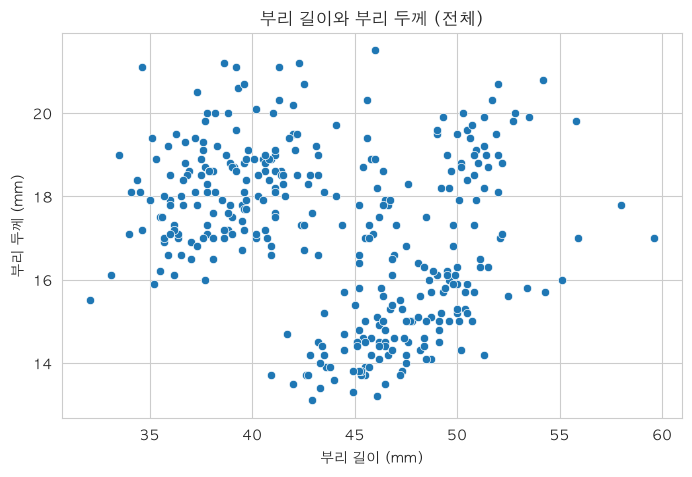

In [4]:
# [문제 1] Q1. 부리 길이(x)와 부리 두께(y)의 산점도 (전체를 한 덩어리로)
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm")  # 점 하나 = 펭귄 한 마리

plt.title("부리 길이와 부리 두께 (전체)")   # 제목
plt.xlabel("부리 길이 (mm)")                 # x축 이름
plt.ylabel("부리 두께 (mm)")                 # y축 이름
plt.show()

### 💻 Q2. 종별 색으로 나눈 산점도

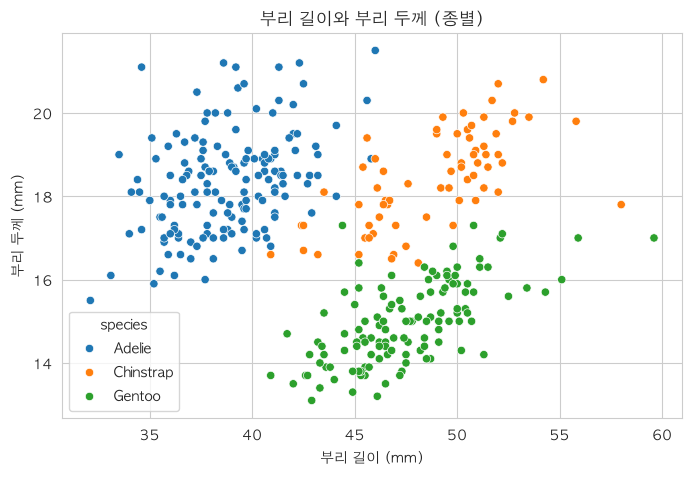

In [5]:
# [문제 1] Q2. 같은 그림을 종(species)별 색으로 나눠 그리기
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm",
                hue="species")               # hue: 색을 나눌 기준 열 (종)

plt.title("부리 길이와 부리 두께 (종별)")
plt.xlabel("부리 길이 (mm)")
plt.ylabel("부리 두께 (mm)")
plt.show()

### 💻 Q3. 상관계수: 전체 vs 종별

In [6]:
# [문제 1] Q3. 상관계수를 '전체'와 '종별'로 구해 부호 비교
pair = ["bill_length_mm", "bill_depth_mm"]

# (1) 전체: 결측이 있는 행은 빼고 두 변수의 상관계수 행렬을 계산
overall = penguins[pair].dropna().corr()
print("[전체] 상관계수")
print(overall.round(3))

# (2) 종별: 종마다 따로 상관계수를 구해서 출력
print("\n[종별] 상관계수 (부리 길이 ↔ 부리 두께)")
for species, group in penguins.groupby("species"):       # 종별로 데이터를 나눔
    r = group[pair].dropna().corr().iloc[0, 1]           # 2x2 행렬에서 (0,1) 값이 두 변수의 r
    print(f"  {species:<10}: r = {r:+.3f}")

[전체] 상관계수
                bill_length_mm  bill_depth_mm
bill_length_mm           1.000         -0.235
bill_depth_mm           -0.235          1.000

[종별] 상관계수 (부리 길이 ↔ 부리 두께)
  Adelie    : r = +0.391
  Chinstrap : r = +0.654
  Gentoo    : r = +0.643


### 📝 해설

**결론: 전체로 보면 약한 음(−)의 관계, 종별로 나누면 세 종 모두 양(+)의 관계다.**

- **전체 r = −0.235**: 부리가 길수록 두께가 얇다고 읽힌다.
- **종별 r = +0.39 ~ +0.65**: 모든 종에서 부리가 길수록 두껍다.
- 부호가 뒤집힌 이유: 종마다 부리의 **기본 크기가 다르다.** Adelie는 길이가 짧고 두께가 두껍고, Gentoo는 길이가 길고 두께가 얇은 편이라, 종을 섞으면 "종 차이"가 "관계"처럼 보인다.

**한 줄 정리:** 숨은 집단 변수(종)를 무시하면 결론이 정반대가 될 수 있으므로, 관계를 볼 때는 **집단을 나눠 확인**한다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. 산점도에서 두 변수는 어떤 방향의 관계로 보였나요?**
→ **전체로 보면 약한 음(−)의 방향**, 하지만 **종별로 보면 세 종 모두 양(+)의 방향**입니다.
- 이유: 점들을 한 덩어리로 보면 전체 흐름이 아래로 기울어 보이지만, 색으로 나누면 종마다 각자 위로 올라가는 띠가 보입니다. 그래서 "그림을 어떻게 나누느냐"가 결론을 바꿉니다.

**Q2. 전체 상관계수의 부호와 Q2 그림의 방향은 일치하나요?**
→ **일치하지 않습니다.** 전체 r = −0.24(음수), 종별 r = +0.39 ~ +0.65(양수)입니다.
- 이유: 종마다 부리의 평균 위치가 다릅니다. Adelie는 부리가 짧고(38.8mm) 두께 18.3mm, Gentoo는 길지만(47.5mm) 매우 얇습니다(15.0mm). Gentoo가 "길고 얇은" 쪽에 몰려 있어서, 종을 섞으면 전체 흐름이 "길수록 얇다"처럼 보입니다. 종별 평균이 놓인 자리가 전체 방향을 뒤집은 것입니다.

**Q3. 종별 상관은 전체 상관과 부호가 같은가, 다른가?**
→ **다릅니다(반대).** 같은 데이터라도 집단을 나누느냐에 따라 부호가 바뀝니다.
- 이유: 집단을 나누면 "종 차이"가 빠지고, 같은 종 안에서의 관계만 남습니다. 이 현상을 **심슨의 역설(Simpson's paradox)**이라고 하며, 숨은 집단 변수가 두 변수 모두에 영향을 줄 때 생깁니다.

**Q4. 같은 데이터인데 전체와 집단별 결론이 정반대로 나온 이유는?**
→ **숨은 집단 변수(종)가 관계를 만들거나 뒤집고 있기 때문입니다.**
- 이유: 종은 부리 길이와 부리 두께 둘 다에 영향을 주는 **교란변수**입니다. 전체 산점도에서는 종 차이가 "부리 길이와 두께의 관계"처럼 보입니다. 이 착시를 걷어내야 진짜 관계가 보입니다.

**Q5. 종 정보가 없었다면 어떤 잘못된 결론을 냈을까요?**
→ **"부리가 길수록 두께가 얇아진다"는 틀린 결론**을 냈을 것입니다.
- 이유: 실제로는 같은 종 안에서 부리가 길수록 두껍습니다. 이런 잘못된 결론을 바탕으로 생물 연구나 보호 정책을 세우면 엉뚱한 판단이 됩니다.

**결론 쓰는 형식:** "종을 무시하면 ○○(음의 관계), 종을 고려하면 ○○(양의 관계)"처럼 두 결과를 나란히 쓰면 정확해집니다.


---
<a id="문제-2"></a>
## 문제 2. 날개가 길면 몸무게도 무거울까?

### 📖 상황
이제 관계를 **숫자 하나**로 요약합니다. 날개 길이(flipper_length_mm)와 몸무게(body_mass_g)를 봅니다.
이 두 변수는 문제 5까지 계속 쓰입니다.

### 🧩 개념
- **피어슨 상관계수 r:** 두 변수가 직선으로 얼마나 함께 움직이는지. 정규분포라는 전제가 필요한 **모수적 방법**입니다.
- **스피어만 상관계수 ρ:** 값 대신 **순위**로 계산. 정규성이 깨져도 쓸 수 있는 **비모수적 방법**입니다.
- **상관계수의 p-값:** "모집단의 상관계수가 0인가?"에 대한 검정입니다. r의 크기와는 다른 질문입니다.

결측치 제거 전: 344 행
결측치 제거 후: 342 행


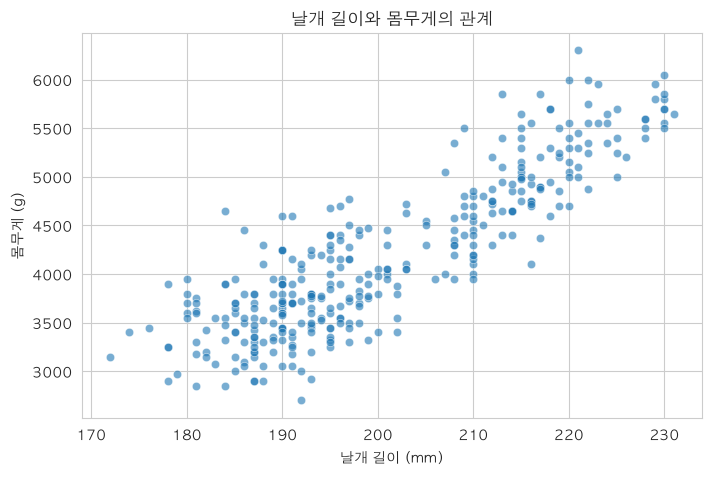

In [7]:
# [문제 2] 날개 길이와 몸무게: 결측 제거 후 데이터 만들기
df_corr = penguins[["flipper_length_mm", "body_mass_g"]].dropna()   # 두 열 모두 있는 행만

print("결측치 제거 전:", len(penguins), "행")
print("결측치 제거 후:", len(df_corr), "행")

# 숫자 전에 그림부터 확인
sns.scatterplot(data=df_corr, x="flipper_length_mm", y="body_mass_g", alpha=0.6)
plt.title("날개 길이와 몸무게의 관계")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

### 💻 Q1. 정규성 검정 (Shapiro-Wilk)

In [8]:
# [문제 2] Q1. 정규성 검정 (Shapiro-Wilk)
# H0: 데이터는 정규분포를 따른다.  p < 0.05면 정규성 기각
for col in ["flipper_length_mm", "body_mass_g"]:
    stat, p = stats.shapiro(df_corr[col])               # 검정통계량과 p-값
    verdict = "정규성 기각 (정규 아님)" if p < 0.05 else "정규성 기각 못함"
    print(f"{col:<18}: W = {stat:.3f}, p = {p:.4f} → {verdict}")

flipper_length_mm : W = 0.952, p = 0.0000 → 정규성 기각 (정규 아님)
body_mass_g       : W = 0.959, p = 0.0000 → 정규성 기각 (정규 아님)


### 💻 Q2. 피어슨 상관계수와 p-값

In [9]:
# [문제 2] Q2. 피어슨 상관계수 r과 p-값
# H0: 모집단 상관계수 = 0 (관계 없음)
r, p_value = stats.pearsonr(df_corr["flipper_length_mm"], df_corr["body_mass_g"])
print(f"피어슨 r = {r:.4f}")
print(f"p-value  = {p_value:.2e}")   # e 표기: 아주 작은 숫자를 읽기 쉽게

피어슨 r = 0.8712
p-value  = 4.37e-107


### 💻 Q3. 스피어만 상관계수와 비교

In [10]:
# [문제 2] Q3. 스피어만 상관계수 (순위 기반, 정규성 가정 불필요)
rho, p_rho = stats.spearmanr(df_corr["flipper_length_mm"], df_corr["body_mass_g"])
print(f"피어슨 r = {r:.4f}   |   스피어만 ρ = {rho:.4f}")
print(f"차이 = {abs(r - rho):.4f}")

피어슨 r = 0.8712   |   스피어만 ρ = 0.8400
차이 = 0.0312


### 💻 Q4. 결과 정리

In [11]:
# [문제 2] Q4. 결과 정리 (값을 출력해 두고 주석으로 해석)
print("정규성 검정 결과 :", "정규성 기각 → 스피어만도 함께 확인" )
print(f"피어슨 r, p-값   : {r:.4f}, {p_value:.2e}")
print(f"스피어만 ρ       : {rho:.4f}")
print("부호 +  → 날개가 길수록 몸무게가 무거운 방향")
print(f"절대값 {abs(r):.2f} → 강한 양의 관계")

정규성 검정 결과 : 정규성 기각 → 스피어만도 함께 확인
피어슨 r, p-값   : 0.8712, 4.37e-107
스피어만 ρ       : 0.8400
부호 +  → 날개가 길수록 몸무게가 무거운 방향
절대값 0.87 → 강한 양의 관계


### 📝 해설

**결론: 날개가 길수록 몸무게가 무거운 강한 양의 관계다 (피어슨 r = 0.87, p < 0.0001).**

- **정규성:** 두 변수 모두 정규성이 기각되었다(p < 0.0001). 그래서 피어슨 단독 결론은 조심해야 한다.
- **그래도 결론은 같다:** 스피어만 ρ = 0.84로 피어슨과 차이가 0.03에 불과하다. 전제 위배의 영향이 작다는 뜻이다.
- **p-값의 의미:** "관계가 있는가"에 대한 답이다. "관계가 강한가"는 r의 크기가 답한다. 둘을 같은 말로 쓰면 안 된다.

**한 줄 정리:** 정규성이 깨졌지만 두 계수가 비슷하므로, 결론("강한 양의 관계")은 그대로 유지해도 된다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. 정규성 검정에서 기각되었는데, 피어슨 상관계수를 쓰면 안 되나요?**
→ **쓸 수는 있지만, 결과를 함께 확인해야 합니다.** 판단 기준은 "정규성이 깨졌는가"가 아니라 **"결론이 바뀌는가"**입니다.
- 이유: 피어슨은 값의 크기 자체로 직선 관계를 재기 때문에, 정규분포에서 크게 벗어난 극단값이 있으면 r을 한쪽으로 끌어당길 수 있습니다. 반면 스피어만은 값 대신 순위로 계산하므로 극단값의 영향이 작습니다.
- 이 데이터: 피어슨 0.871, 스피어만 0.840으로 차이가 0.03뿐입니다. 결론("강한 양의 관계")이 같으므로, 피어슨 결과를 쓰되 스피어만을 함께 제시하면 충분합니다.

**Q2. 두 계수가 비슷하면 무엇을 뜻하고, 다르면 무엇을 의심해야 하나요?**
→ **비슷하면 전제 위배의 영향이 작다는 뜻**이고, **많이 다르면 이상치나 곡선 관계를 의심**해야 합니다.
- 이유: 두 계수가 다른 이유는 크게 두 가지입니다. ① 극단값이 피어슨을 끌어당김 ② 관계가 직선이 아니라 곡선이라서 피어슨이 과소 평가됨. 이때는 산점도로 어떤 점이 튀는지, 모양이 휘었는지부터 확인합니다.

**Q3. 상관계수의 p-값은 무엇에 대한 검정이고, "상관이 크다"와 "상관이 유의하다"는 같은 말인가요?**
→ **p-값은 "모집단의 상관계수가 0인가?"를 검정**합니다. 두 말은 **같지 않습니다.**
- 이유: 상관의 크기(r)는 관계가 얼마나 강한지를, 유의성(p)은 그 관계가 우연이 아닐 가능성을 말합니다. 유의성은 **표본 크기 n에도 좌우**됩니다. 이 데이터(n = 342)에서는 r이 0.1 정도만 되어도 p < 0.05가 됩니다. 그래서 표본이 크면 아주 약한 관계도 "유의하다"고 나올 수 있습니다.

**Q4. 날개 길이가 몸무게의 원인이라고 결론 내릴 수 있나요?**
→ **아니요, 상관만으로는 인과를 말할 수 없습니다.** 다음 세 가지 설명이 모두 가능합니다.
- **교란변수:** 종(또는 성별)이 날개와 몸무게를 동시에 키울 수 있습니다. 큰 종은 날개도 길고 몸도 큽니다. 실제로 성별 평균 몸무게는 수컷 4,546g, 암컷 3,862g으로 차이가 큽니다.
- **역인과(방향 불명):** 날개와 몸무게가 함께 자라는 과정이라 어느 쪽이 먼저인지 데이터만으로 알 수 없습니다.
- **우연 또는 표본 편향:** 이 표본(남극 3개 섬)에서만 나타난 패턴일 수 있습니다.
인과를 주장하려면 실험이나 교란변수를 통제한 분석이 필요합니다.


---
<a id="문제-2-종별"></a>
## 문제 2 확장. 종별로 나눠 보면 결론이 어떻게 달라질까?

### 📖 상황
문제 1에서 보았듯이 펭귄은 **세 종(Adelie, Chinstrap, Gentoo)**이 섞여 있습니다. 전체 342마리로 구한 r = 0.87이 **종 안에서도 같을까요?**
문제 2와 **같은 순서(Step 1~6)**로 종별로 다시 분석합니다.

| Step | 하는 일 | 전체 분석 | 종별 분석 |
|---|---|---|---|
| 1 | 데이터 준비 | 결측 제거 | 결측 제거 + 종별 개수 확인 |
| 2 | 그림 | 산점도 | 종별 색으로 나눈 산점도 |
| 3 | 정규성 | Shapiro-Wilk | **종마다** Shapiro-Wilk |
| 4 | 피어슨 | r, p-값 | **종마다** r, p-값 |
| 5 | 스피어만 | ρ | **종마다** ρ |
| 6 | 비교·정리 | 결론 | 전체와 종별 비교 |

### 🧩 개념
- **집단별 분석(stratified analysis):** 전체를 한 덩어리로 보지 않고, 집단별로 나눠서 같은 분석을 반복하는 방법.
- **종 안에서의 관계 vs 종 사이의 차이:** 전체 상관은 "종 안의 관계"와 "종 사이의 차이"가 섞여서 나옵니다. 종별 분석은 앞의 것만 따로 봅니다.
- **표본이 작은 집단:** 종별로 나누면 n이 줄어듭니다(Chinstrap은 68마리). 검정력이 낮아지므로 p-값 해석에 더 주의합니다.


분석 대상: 342 행
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


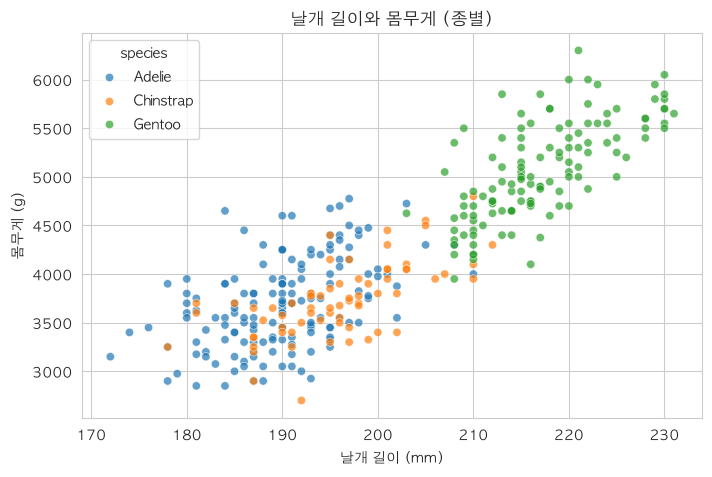

In [12]:
# [문제 2 확장] 종별로 보기 · Step 1. 데이터 준비
# 전체 분석과 같은 방식: 날개 길이·몸무게·종이 모두 있는 행만 사용
penguins = sns.load_dataset("penguins")                 # 문제 1에서 이미 불러왔다면 생략 가능
df_sp = penguins[["species", "flipper_length_mm", "body_mass_g"]].dropna()

print("분석 대상:", len(df_sp), "행")
print(df_sp["species"].value_counts())          # 종별 표본 크기 확인 (n이 작으면 결과가 흔들림)

# Step 2. 그림으로 먼저 확인: 같은 산점도를 종별 색으로 나누기
sns.scatterplot(data=df_sp, x="flipper_length_mm", y="body_mass_g",
                hue="species", alpha=0.7)       # hue: 종마다 다른 색
plt.title("날개 길이와 몸무게 (종별)")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

In [13]:
# [문제 2 확장] Step 3. 정규성 검정 (Shapiro-Wilk) — 종마다, 변수마다
# H0: 데이터는 정규분포를 따른다. p < 0.05면 정규성 기각
for species, g in df_sp.groupby("species"):              # 종별로 나눠서 검정
    print(f"[{species}]  (n = {len(g)})")
    for col in ["flipper_length_mm", "body_mass_g"]:
        stat, p = stats.shapiro(g[col])                  # 검정통계량 W와 p-값
        verdict = "정규성 기각" if p < 0.05 else "정규성 기각 못함"
        print(f"   {col:<18}: W = {stat:.3f}, p = {p:.4f} → {verdict}")

[Adelie]  (n = 151)
   flipper_length_mm : W = 0.993, p = 0.7200 → 정규성 기각 못함
   body_mass_g       : W = 0.981, p = 0.0324 → 정규성 기각
[Chinstrap]  (n = 68)
   flipper_length_mm : W = 0.989, p = 0.8106 → 정규성 기각 못함
   body_mass_g       : W = 0.984, p = 0.5605 → 정규성 기각 못함
[Gentoo]  (n = 123)
   flipper_length_mm : W = 0.962, p = 0.0016 → 정규성 기각
   body_mass_g       : W = 0.986, p = 0.2336 → 정규성 기각 못함


In [14]:
# [문제 2 확장] Step 4~5. 종별 피어슨 r(p-값)과 스피어만 ρ(p-값) 구하기
rows = []                                              # 결과를 한 행씩 모을 리스트
for species, g in df_sp.groupby("species"):
    r, p_r = stats.pearsonr(g["flipper_length_mm"], g["body_mass_g"])     # 피어슨 (값 기반)
    rho, p_rho = stats.spearmanr(g["flipper_length_mm"], g["body_mass_g"]) # 스피어만 (순위 기반)
    rows.append({"종": species, "n": len(g),
                 "피어슨 r": round(r, 3), "r의 p-값": f"{p_r:.1e}",
                 "스피어만 ρ": round(rho, 3), "ρ의 p-값": f"{p_rho:.1e}"})

result_sp = pd.DataFrame(rows)     # 표로 한 번에 보기
result_sp

,종,n,피어슨 r,r의 p-값,스피어만 ρ,ρ의 p-값
0,Adelie,151,0.468,1.3e-09,0.475,6.8e-10
1,Chinstrap,68,0.642,3.7e-09,0.670,4.0e-10
2,Gentoo,123,0.703,1.3e-19,0.717,1.2e-20


In [15]:
# [문제 2 확장] Step 6. 전체 vs 종별 비교 (결론이 어떻게 달라지는지 확인)
r_all, p_all = stats.pearsonr(df_sp["flipper_length_mm"], df_sp["body_mass_g"])
rho_all, _ = stats.spearmanr(df_sp["flipper_length_mm"], df_sp["body_mass_g"])

print(f"[전체 342마리]  피어슨 r = {r_all:.3f}  |  스피어만 ρ = {rho_all:.3f}")
print("[종별]")
for species, g in df_sp.groupby("species"):
    r_s = stats.pearsonr(g["flipper_length_mm"], g["body_mass_g"])[0]
    print(f"   {species:<10}: 피어슨 r = {r_s:.3f}")

# 판정: 전체와 종별 모두 같은 부호(+)인가?
signs = [np.sign(stats.pearsonr(g["flipper_length_mm"], g["body_mass_g"])[0])
         for _, g in df_sp.groupby("species")]
print("\n모든 종에서 양(+)의 관계인가?:", all(s > 0 for s in signs))

[전체 342마리]  피어슨 r = 0.871  |  스피어만 ρ = 0.840
[종별]
   Adelie    : 피어슨 r = 0.468
   Chinstrap : 피어슨 r = 0.642
   Gentoo    : 피어슨 r = 0.703

모든 종에서 양(+)의 관계인가?: True


## 📊 종별 결과 요약

| 종 | n | 피어슨 r | 스피어만 ρ |
|---|---|---|---|
| Adelie | 151 | 0.468 | 0.475 |
| Chinstrap | 68 | 0.642 | 0.670 |
| Gentoo | 123 | 0.703 | 0.717 |
| **전체** | **342** | **0.871** | **0.840** |

### 📝 해설

**결론: 세 종 모두에서 날개가 길수록 몸무게가 무거운 양의 관계가 있다. 다만 종 안에서의 관계 강도(r = 0.47~0.70)는 전체 r(0.87)보다 작다.**

- **방향은 일관됨:** 모든 종에서 r > 0, 모든 p-값 < 0.001이다. 종을 가리지 않는 공통 경향이다.
- **강도는 줄어듦:** 전체 r = 0.87은 종 안의 관계보다 크다. Gentoo는 날개도 길고(217mm) 몸도 무겁다(약 5,076g). 이 **종 사이 차이**가 전체 산점도를 더 가파르게 보이게 만든 것이다.
- **왜 종별로 나누면 종 안에서의 관계 강도가 줄어드는가?:** 종별로 나누면 날개 길이와 몸무게 각각의 흩어짐이 작아진다. 종 사이의 큰 차이가 빠지고, 같은 종 안에서 펭귄마다 다른 차이만 남기 때문이다. 흩어짐이 작아진 상태에서 관계를 재면 r이 낮게 나올 수 있다.
- **정규성:** 종별로는 일부만 기각되었다(Adelie 몸무게, Gentoo 날개 길이). 그래도 피어슨과 스피어만 값이 거의 같아(예: Gentoo 0.703 vs 0.717) 결론은 바뀌지 않는다.
- **표본이 작은 Chinstrap(n = 68)도 p ≈ 4×10⁻⁹:** 표본이 적은데도 불구하고 날개길이와 몸무게의 관계가 강하서 (뚜렷해서) 우연으로 보기 어렵다. 문제 4 Q5의 Adelie 부리 사례는 관계가 약해서 표본수가 비슷해도 확실한 결론을 내리지 못했다.

**한 줄 정리:** 날개가 길수록 몸무게가 무겁다는 방향은 모든 종에서 같다. 다만 전체 r(0.87)은 종 차이가 섞여 과대 평가되어 있으므로, 종 안의 관계는 0.47~0.70으로 보고해야 정확하다.

## ✅ 결론

- **방향:** 세 종 모두 날개가 길수록 몸무게가 무거운 **양의 관계**이며, 모든 p-값이 0.001보다 작습니다.
- **강도:** 전체 r(0.87)은 종 안의 관계(0.47~0.70)보다 큽니다.
- **이유:** Gentoo는 날개도 길고 몸도 무겁습니다. 이 **종 차이**가 전체 상관을 부풀린 것입니다.

> 📌 날개 길이와 몸무게의 방향은 종과 무관하게 일정하지만, 관계의 강도는 종 안에서 보고해야 정확합니다.
- 전체 r = 0.87: 종 차이까지 포함한 값이다. "날개 길이가 긴 펭귄일수록 몸무게가 무겁다"는 큰 그림에 가깝다.
- 종별 r = 0.47~0.70: 같은 종 안에서 날개 길이가 몸무게를 얼마나 설명하는지에 가깝다.
- 보고서에는 두 값을 함께 적고, 전체 r이 종 차이에 영향을 받았다는 점을 밝히는 것이 정확하다.




---
<a id="문제-3"></a>
## 문제 3. 그 관계를 하나의 식으로 만들 수 있을까?

### 📖 상황
상관계수는 "관계가 얼마나 강한가"만 알려 줍니다. "날개가 1mm 길면 몸무게가 **몇 g** 늘어나는가"는 답하지 못합니다.
그 답을 주는 것이 **선형회귀**입니다. 흩어진 점들을 가장 잘 지나가는 직선 **y = a + bx**를 찾습니다.

### 🧩 개념
- **OLS(최소제곱법, Ordinary Least Squares):** 실제값과 예측선의 차이(잔차)를 제곱해 더한 값이 가장 작은 직선을 찾는 방법.
- **회귀식 읽기:** 절편 a = x가 0일 때 예측값, 기울기 b = x가 1 늘 때 y의 변화량.
- **상관과 회귀의 관계:** 기울기는 상관계수에 **두 변수의 표준편차 비**를 곱한 것과 같습니다(Q5에서 확인).

In [16]:
# [문제 3] 데이터 준비: 날개 길이와 몸무게 둘 다 있는 행만 사용
penguins_cleaned = penguins.dropna(subset=["body_mass_g", "flipper_length_mm"])
print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 같은가?:", len(penguins_cleaned) == len(df_corr))

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 같은가?: True


### 💻 Q1. 단순회귀 모형 적합

In [17]:
# [문제 3] Q1. 단순회귀 모형 적합: 몸무게 = a + b × 날개길이
# 'y ~ x' 형태: 왼쪽이 결과(반응변수), 오른쪽이 원인 후보(설명변수)
model = smf.ols(formula="body_mass_g ~ flipper_length_mm",
                data=penguins_cleaned).fit()   # ols: 최소제곱법으로 직선 찾기, fit: 실제 계산

### 💻 Q2. 결과표 출력 (coef, P>|t|, R-squared 위치 확인)

In [18]:
# [문제 3] Q2. 결과표 출력
# 주요 열: coef(계수), P>|t|(계수의 p-값), R-squared(결정계수)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        14:25:31   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.81

### 💻 Q3. 회귀식 완성

In [19]:
# [문제 3] Q3. 회귀식 완성: 결과표에서 절편과 기울기 값 꺼내기
a = model.params["Intercept"]              # 절편: x가 0일 때 예측값
b = model.params["flipper_length_mm"]      # 기울기: x가 1 늘 때 y가 변하는 양

print(f"절편(a) = {a:.2f}")
print(f"기울기(b) = {b:.2f}")
print(f"회귀식: 몸무게(g) = {a:.2f} + {b:.2f} × 날개길이(mm)")

절편(a) = -5780.83
기울기(b) = 49.69
회귀식: 몸무게(g) = -5780.83 + 49.69 × 날개길이(mm)


### 💻 Q4. 10mm 차이의 의미

In [20]:
# [문제 3] Q4. 날개가 평균보다 10mm 긴 펭귄의 몸무게 차이
mean_flipper = penguins_cleaned["flipper_length_mm"].mean()   # 날개 길이 평균
diff_10 = b * 10                                              # 10mm 차이 × 기울기

print(f"날개 평균: {mean_flipper:.1f} mm")
print(f"평균보다 10mm 긴 펭귄은 평균적으로 몸무게가 {diff_10:.1f} g 더 무겁다")

날개 평균: 200.9 mm
평균보다 10mm 긴 펭귄은 평균적으로 몸무게가 496.9 g 더 무겁다


### 💻 Q5. 상관과 회귀를 잇는 두 관계식 확인

In [21]:
# [문제 3] Q5. 상관과 회귀를 잇는 두 관계식 확인
r_flip, _ = stats.pearsonr(df_corr["flipper_length_mm"], df_corr["body_mass_g"])
sd_x = penguins_cleaned["flipper_length_mm"].std(ddof=1)   # x의 표준편차
sd_y = penguins_cleaned["body_mass_g"].std(ddof=1)         # y의 표준편차

# ① 기울기 = r × (s_y / s_x)
left1, right1 = b, r_flip * (sd_y / sd_x)
# ② R² = r² (단순회귀에서만 성립)
left2, right2 = model.rsquared, r_flip ** 2

print(f"① 기울기 b       = {left1:.4f}   |  r × (s_y/s_x) = {right1:.4f}")
print(f"② R²             = {left2:.4f}   |  r²            = {right2:.4f}")

① 기울기 b       = 49.6856   |  r × (s_y/s_x) = 49.6856
② R²             = 0.7590   |  r²            = 0.7590


### 📝 해설

**결론: 회귀식은 몸무게 = −5780.8 + 49.7 × 날개 길이이며, 날개가 10mm 길면 평균 약 497g 더 무겁다.**

- **기울기 b = 49.7:** 날개 1mm당 몸무게가 평균 49.7g 늘어난다.
- **절편 a = −5780.8:** 음수다. 날개 길이 0mm인 펭귄은 존재하지 않으므로 **의미 없는 값**이다. 회귀식은 관측 범위(약 170~230mm) 안에서만 쓴다.
- **Q5 확인:** 기울기 = r × (s_y ÷ s_x) = 49.69로 일치, R² = r² = 0.759로 일치. 상관과 회귀는 같은 뿌리의 두 얼굴이다.

**한 줄 정리:** 상관은 "강도", 회귀는 "단위당 변화량"을 준다. 보고서에 "1mm당 ○g"을 쓸 수 있는 것은 회귀뿐이다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. 기울기 b = 49.7을 한 문장으로 풀면?**
→ **"날개 길이가 1mm 길면, 몸무게가 평균적으로 49.7g 무거운 경향이 있다."**
- 이유: 회귀는 개체 하나하나가 아니라 **평균적인 경향**을 말합니다. 같은 날개 길이라도 펭귄마다 몸무게는 다를 수 있습니다. 또 "경향"이므로 인과("날개가 길어서 무거워진다")로 바로 옮기면 안 됩니다(문제 2 Q4 참고).

**Q2. 절편 a = −5780.8을 "날개 길이 0mm인 펭귄의 몸무게"로 해석해도 되나요?**
→ **안 됩니다.** 절편은 계산을 위한 기준점일 뿐 실제 의미를 갖지 않습니다.
- 이유 ①: 우리 데이터의 날개 길이는 약 170~230mm입니다. 0mm는 관측 범위 **밖**이라 그 근처에서도 직선이 맞는다는 보장이 없습니다.
- 이유 ②: 몸무게가 음수가 되는 것은 현실에서 불가능합니다. 음수는 "직선을 연장하면 생기는 수학적 결과"일 뿐입니다.
- 원칙: 회귀식은 **관측된 범위 안에서만** 예측에 씁니다.

**Q3. x와 y를 바꿔 분석하면 기울기와 R²는 같을까요?**
→ **기울기는 달라지고, R²는 같습니다.**
- 이유: 기울기는 β = r × (s_y ÷ s_x)입니다. x와 y를 바꾸면 분모와 분자가 바뀌어 기울기가 달라집니다. 하지만 R² = r²이고, r은 두 변수에 대해 대칭이라 R²도 같습니다. 즉 **설명력은 대칭이지만, 변화량(단위가 있는 기울기)은 방향에 따라 달라집니다.**

**Q4. 회귀는 상관계수보다 무엇을 더 알려 주나요?**
→ **단위가 있는 변화량과 예측값**을 알려 줍니다.
- 이유: 상관계수 0.87은 "강하다"까지만 말합니다. 회귀는 "날개 1mm당 49.7g", "10mm 더 긴 펭귄은 약 497g 더 무겁다"처럼 실제 단위로 말할 수 있어서 보고서와 예측에 쓸 수 있습니다. 상관계수는 단위가 없어 이런 계산이 불가능합니다.


---
<a id="문제-4"></a>
## 문제 4. 이 기울기, 우연이 아니라고 말할 수 있을까?

### 📖 상황
기울기 49.7은 342마리 표본에서 계산한 값입니다. 전체 펭귄 집단에서 두 변수가 **실제로 아무 관계가 없다면(기울기 = 0)**, 이 값은 표본을 뽑다가 우연히 생긴 것일 수도 있습니다.
이 의심에 답하는 것이 **회귀계수 검정**이고, 결과표의 **P>|t|** 열이 근거입니다.

### 🧩 개념
- **귀무가설 H₀:** 기울기 = 0 (x와 y는 선형 관계가 없다)
- **대립가설 H₁:** 기울기 ≠ 0
- **t-통계량:** 기울기를 그 표준오차로 나눈 값. 클수록 우연으로 보기 어렵다.
- **상관 검정과 회귀 검정은 같은 검정:** 단순회귀에서 둘의 t값과 p값이 같아진다.
- **기각 실패 ≠ 무관 증명:** 증거가 부족했다는 뜻이지 관계가 없다는 뜻이 아니다.

### 💻 Q1. 가설 세우기

```
# H₀ (귀무가설): 날개 길이의 기울기 = 0 (몸무게와 선형 관계가 없다)
# H₁ (대립가설): 날개 길이의 기울기 ≠ 0 (몸무게와 선형 관계가 있다)
```

### 💻 Q2. 기울기의 p-값 찾기

In [22]:
# [문제 4] Q2. 기울기의 p-값 찾기 (결과표의 P>|t| 열)
p_slope = model.pvalues["flipper_length_mm"]
print(f"기울기의 p-값 = {p_slope:.2e}")

기울기의 p-값 = 4.37e-107


### 💻 Q3. 유의수준 0.05로 판정

In [23]:
# [문제 4] Q3. 유의수준 0.05로 판정
alpha = 0.05                                   # 유의수준 (1종 오류 허용 한도)
if p_slope < alpha:
    print(f"p({p_slope:.2e}) < α({alpha}) → H0 기각: 기울기는 0이 아니다 (관계 있음)")
else:
    print(f"p({p_slope:.4f}) ≥ α({alpha}) → H0 기각 못함: 관계가 있다는 증거 부족")

p(4.37e-107) < α(0.05) → H0 기각: 기울기는 0이 아니다 (관계 있음)


### 💻 Q4. 공식으로 t 계산 → 결과표 t와 비교

In [24]:
# [문제 4] Q4. 상관계수 검정 공식으로 t 직접 계산 → 회귀 결과표의 t와 비교
n = len(penguins_cleaned)                       # 표본 크기
t_manual = r_flip * np.sqrt(n - 2) / np.sqrt(1 - r_flip ** 2)   # t = r√(n−2) / √(1−r²)
t_model = model.tvalues["flipper_length_mm"]    # 회귀 결과표의 t값

print(f"공식으로 계산한 t = {t_manual:.4f}")
print(f"회귀 결과표의 t   = {t_model:.4f}")
print("→ 두 값이 같다. 상관 검정과 기울기 검정은 같은 검정이다.")

공식으로 계산한 t = 32.7222
회귀 결과표의 t   = 32.7222
→ 두 값이 같다. 상관 검정과 기울기 검정은 같은 검정이다.


### 💻 Q5. p-값이 크게 나오는 사례 (Adelie 수컷, 부리 길이)

In [25]:
# [문제 4] Q5. Adelie 수컷만 골라 bill_length_mm → body_mass_g 회귀
adelie_male = penguins.dropna(subset=["bill_length_mm", "body_mass_g"])   # 결측 제거
adelie_male = adelie_male[(adelie_male["species"] == "Adelie") &
                          (adelie_male["sex"] == "Male")]                 # 종·성별 조건

m2 = smf.ols(formula="body_mass_g ~ bill_length_mm", data=adelie_male).fit()

print(f"표본 크기 n = {len(adelie_male)}")
print(f"R²          = {m2.rsquared:.3f}")
print(f"기울기 p-값 = {m2.pvalues['bill_length_mm']:.4f}")
if m2.pvalues["bill_length_mm"] < alpha:
    print("→ 유의함 (H0 기각)")
else:
    print("→ 유의하지 않음 (H0 기각 못함)")

표본 크기 n = 73
R²          = 0.049
기울기 p-값 = 0.0610
→ 유의하지 않음 (H0 기각 못함)


### 📝 해설

**결론: 날개 길이와 몸무게의 기울기는 0이 아니다 (p ≈ 4×10⁻¹⁰⁷). 반면 Adelie 수컷의 부리 길이 기울기는 유의하지 않다 (p = 0.061).**

- **Q2~Q3:** 날개 길이 기울기의 p-값은 아주 작아 H₀를 기각한다. 우연으로 보기 어렵다.
- **Q4:** 공식으로 계산한 t = 32.72가 결과표의 t = 32.72와 정확히 같다. 상관 검정과 회귀 검정은 같은 검정이다.
- **Q5:** 같은 penguins 데이터인데 결론이 갈렸다.
  - 표본이 73마리로 작다.
  - R² = 0.049로 설명력이 거의 없다. 부리 길이가 몸무게 변동의 5%도 설명하지 못한다.
  - 그래서 "관계가 없다"가 아니라 **"관계가 있다는 증거가 부족하다"**로 읽어야 한다.

**한 줄 정리:** p-값은 표본 크기와 관계의 강도에 따라 달라진다. 큰 표본에서는 작은 관계도 유의하고, 작은 표본에서는 큰 관계도 놓칠 수 있다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. p-값이 작다는 것은 정확히 무엇이 작다는 뜻이고, "귀무가설이 참일 확률"이라고 말해도 되나요?**
→ **"H₀가 참이라고 가정했을 때 이런 결과가 나올 확률"이 작다는 뜻입니다. "H₀가 참일 확률"이라고 말하면 틀립니다.**
- 이유: p-값은 "H₀가 참"이라는 **가정을 먼저 둔 뒤** 데이터를 보고 계산합니다. 방향이 거꾸로입니다. H₀가 참일 확률을 알려면 "애초에 H₀가 그럴듯한가"에 대한 사전 정보가 필요한데, p-값에는 그 정보가 없습니다.

**Q2. Q4에서 공식의 t와 결과표의 t가 같았습니다. 무엇을 뜻하나요?**
→ **상관 검정과 기울기 검정은 같은 검정을 다른 방식으로 쓴 것입니다.**
- 이유: 단순회귀에서 "기울기 = 0"과 "상관계수 = 0"은 같은 질문입니다. 두 식을 정리하면 t = r√(n−2) ÷ √(1−r²)로 같아지므로 t값도 p-값도 같습니다.

**Q3. Q2(날개, n = 342, p 매우 작음)와 Q5(부리, n = 73, p = 0.061)의 결론이 갈린 이유는?**
→ **표본 크기와 관계의 강도 두 가지 때문입니다.**
- 표본 크기: 표본이 크면 작은 차이도 잡아내고, 작으면 같은 크기의 관계도 놓치기 쉽습니다. Q5는 73마리뿐입니다.
- 관계의 강도: 날개 길이는 몸무게 변동의 **76%**(R² = 0.759)를 설명하지만, Q5의 부리 길이는 **5%**(R² = 0.049)만 설명합니다. 강한 관계는 적은 표본으로도 드러나지만, 약한 관계는 표본이 적으면 묻힙니다.
- 같은 데이터라도 "어떤 집단을, 몇 마리를, 어떤 변수로" 보느냐에 따라 결론이 달라진다는 점을 기억하세요.

**Q4. p-값이 0.05보다 조금 클 때 "두 변수는 관계가 없음이 증명되었다"고 말할 수 있나요?**
→ **아니요. "관계가 있다는 증거가 부족하다"가 정확한 표현입니다.**
- 이유: 기각하지 못한 것은 "관계 없음"을 증명한 것이 아니라 **증거를 찾지 못한 것**입니다. 표본이 작으면 실제 관계가 있어도 놓칠 수 있습니다(2종 오류). Q5처럼 p = 0.061은 0.05에 가까워서 "관계가 약하게 있을 수도 있다"는 여지가 남습니다.
- 권장 문장: "이 표본(n = 73)에서는 부리 길이와 몸무게의 선형 관계를 유의수준 0.05에서 확인하지 못했다(p = 0.061). 표본을 늘려 재검증이 필요하다."


---
<a id="문제-5"></a>
## 문제 5. 미니 프로젝트: 이 회귀모형, 믿고 보고해도 될까?

### 📖 상황
계수가 유의하다고 분석이 끝난 것은 아닙니다. 보고서를 쓰기 전에 두 가지를 확인합니다.
1. **얼마나 설명하는가:** 결정계수 R²
2. **전제가 지켜졌는가:** 잔차 진단

### 🧩 개념
- **잔차(Residual):** 실제값 − 예측값. 모형이 설명하지 못한 부분.
- **좋은 잔차:** 0 주위에 패턴 없이 고르게 흩어진 모습.
- **이분산성(Heteroscedasticity):** 예측값에 따라 잔차의 흩어짐이 달라지는 것. 깔때기 모양이 대표적. 이때 p-값과 신뢰구간을 그대로 믿기 어렵다.
- **브루쉬-페이건 검정(Breusch-Pagan):** H₀는 "등분산이다". p < 0.05면 이분산을 의심한다.
- **비교군 설계:** 문제가 있는 모형을 일부러 나란히 놓으면, 좋은 잔차와 나쁜 잔차의 차이가 보인다.

In [26]:
# 문제 5 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행")
print("모형: body_mass_g ~ flipper_length_mm")

분석 대상 데이터: 342 행
모형: body_mass_g ~ flipper_length_mm


### 💻 Q1. 결정계수 R²

In [27]:
# [문제 5] Q1. 결정계수 R²: 몸무게 변동 중 모형이 설명한 비율
print(f"R-squared = {model.rsquared:.4f}")
print(f"→ 몸무게 변동의 약 {model.rsquared * 100:.1f}%를 날개 길이로 설명한다.")

R-squared = 0.7590
→ 몸무게 변동의 약 75.9%를 날개 길이로 설명한다.


### 💻 Q2. 예측값과 잔차 계산

In [28]:
# [문제 5] Q2. 예측값과 잔차 계산
fitted = model.fittedvalues     # 예측값: 모형이 예측한 몸무게
resid = model.resid             # 잔차: 실제값 − 예측값

print(f"잔차 개수: {len(resid)}")
print(f"잔차 평균: {resid.mean():.2e}  (0에 가까워야 정상)")

잔차 개수: 342
잔차 평균: 2.31e-11  (0에 가까워야 정상)


### 💻 Q3. 잔차 산점도

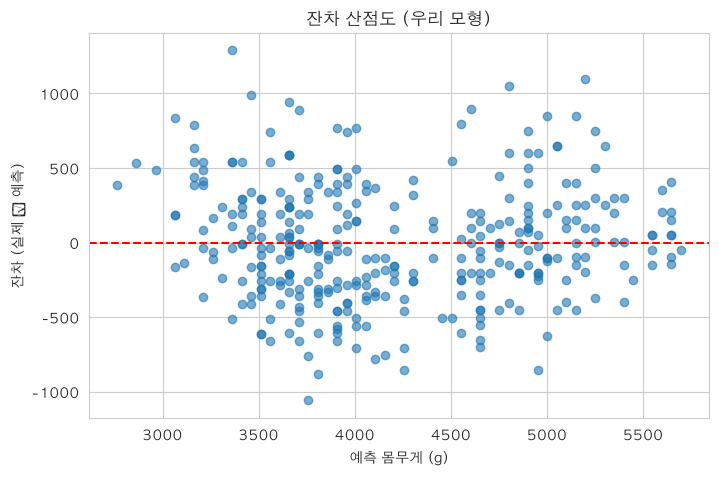

In [29]:
# [문제 5] Q3. 잔차 산점도: 가로 = 예측값, 세로 = 잔차
plt.scatter(fitted, resid, alpha=0.6)            # 점 하나 = 펭귄 한 마리의 잔차
plt.axhline(0, color="red", linestyle="--")      # 0 기준선: 여기 주변에 고르게 흩어져야 좋음
plt.title("잔차 산점도 (우리 모형)")
plt.xlabel("예측 몸무게 (g)")
plt.ylabel("잔차 (실제 − 예측)")
plt.show()

### 💻 Q4. 브루쉬-페이건 검정

In [34]:
# [문제 5] Q4. 브루쉬-페이건 검정: 등분산성 확인
# H0: 등분산이다 (잔차의 흩어짐이 일정하다)
lm_stat, lm_p, f_stat, f_p = het_breuschpagan(resid, model.model.exog)
print(f"Breusch-Pagan LM 통계량 = {lm_stat:.4f}")
print(f"Breusch-Pagan LM p-value = {lm_p:.4f}")
print(f"Breusch-Pagan F 통계량 = {f_stat:.4f}")
print(f"Breusch-Pagan F p-value = {f_p:.4f}")
if lm_p < 0.05:
    print("→ H0 기각: 이분산 의심 (p-값과 신뢰구간을 그대로 믿기 어려움)")
else:
    print("→ H0 기각 못함: 등분산 가정 문제 없음")

Breusch-Pagan LM 통계량 = 2.1579
Breusch-Pagan LM p-value = 0.1418
Breusch-Pagan F 통계량 = 2.1589
Breusch-Pagan F p-value = 0.1427
→ H0 기각 못함: 등분산 가정 문제 없음


### 💻 Q5. 비교군 모형과 나란히 비교

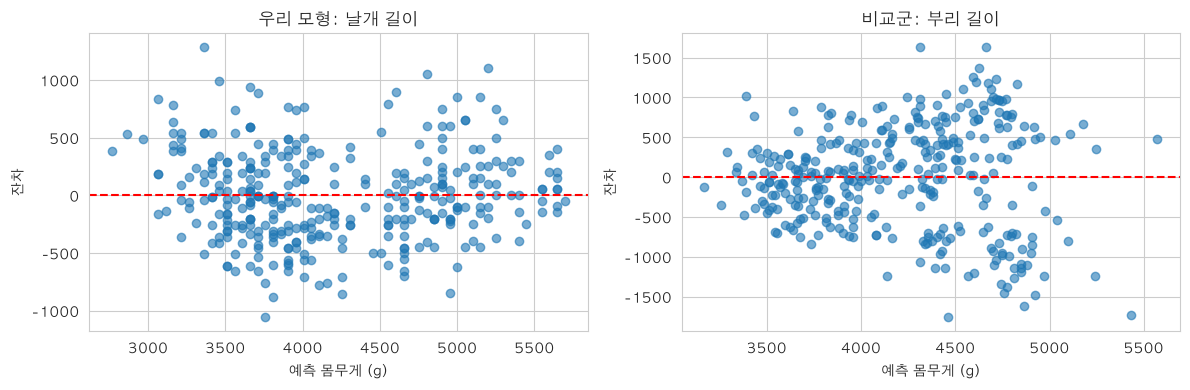

우리 모형(날개)  BP p-value = 0.1418
비교군(부리)     BP p-value = 0.0000


In [31]:
# [문제 5] Q5. 비교군 모형: 몸무게 ~ 부리 길이 (문제가 있는 모형과 비교)
model_bill = smf.ols(formula="body_mass_g ~ bill_length_mm",
                     data=penguins.dropna(subset=["body_mass_g", "bill_length_mm"])).fit()
resid_bill = model_bill.resid
fitted_bill = model_bill.fittedvalues

# 두 잔차 산점도를 옆으로 나란히
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(fitted, resid, alpha=0.6)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_title("우리 모형: 날개 길이")
ax[1].scatter(fitted_bill, resid_bill, alpha=0.6)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_title("비교군: 부리 길이")
for a_ in ax:
    a_.set_xlabel("예측 몸무게 (g)")
    a_.set_ylabel("잔차")
plt.tight_layout()
plt.show()

# 두 모형의 브루쉬-페이건 p-값 비교
_, p_bill, _, _ = het_breuschpagan(resid_bill, model_bill.model.exog)
_, p_flip, _, _ = het_breuschpagan(resid, model.model.exog)
print(f"우리 모형(날개)  BP p-value = {p_flip:.4f}")
print(f"비교군(부리)     BP p-value = {p_bill:.4f}")

### 📝 해설

**결론: 날개 길이 모형은 몸무게 변동의 약 76%를 설명하고, 잔차의 등분산 가정도 문제가 없어 보고해도 된다. 다만 잔차에 종별 덩어리가 보여 종 변수를 놓쳤을 가능성이 있다.**

- **Q1 R² = 0.759:** 몸무게 변동의 약 76%를 날개 길이로 설명한다. 나머지 24%는 설명되지 않은 부분이다.
- **Q2 잔차 평균 ≈ 0:** 회귀에서 잔차 평균은 항상 0에 가깝다. 정상이다.
- **Q3 잔차 산점도:** 0 주위에 고르게 퍼져 있고 뚜렷한 깔때기 모양은 없다. 다만 몇 개의 덩어리가 보인다.
- **Q4 BP p = 0.142:** H₀를 기각하지 못해 등분산 가정은 문제가 없다.
- **Q5 비교군(부리 길이):** BP p ≈ 0.000으로 이분산이 뚜렷하다. 잔차가 가운데에서 퍼졌다가 좁아지는 깔때기 모양이다. 같은 데이터라도 설명변수를 바꾸면 진단 결과가 달라진다.

**보고 문장 (예시):**
> 날개 길이는 몸무게를 유의하게 설명했다(기울기 49.7 g/mm, p < 0.001, R² = 0.76). 잔차의 등분산 검정은 문제가 없었으나(BP p = 0.14), 종별 잔차 덩어리가 보여 종 변수를 포함한 다중회귀가 필요하다.

### 🧠 데이터를 어떻게 읽을까요?

**Q1. 잔차 산점도 상태는? 이 결과로 앞의 기울기와 p-값 해석을 믿어도 되나요?**
→ **대체로 믿을 수 있습니다.** 잔차가 0 주위에 고르게 흩어져 있고 뚜렷한 깔때기 모양이 없으며, 등분산 검정도 통과했기 때문입니다(BP p = 0.14).
- 다만 **종별로 묶인 덩어리**가 남아 있어 완벽하지는 않습니다.
- 이유: 잔차에 패턴이 남아 있다는 것은 모형이 설명하지 못한 **체계적인 요인**(예: 종)이 있다는 신호입니다. 그래서 결론은 "날개 길이의 효과는 유의하다"로 쓰되, "몸무게의 원인은 날개 길이뿐이다"라고 쓰면 안 됩니다.

**Q2. Q5의 두 잔차 산점도는 어떻게 달랐고, 그 모양을 무엇이라 부르나요?**
→ **부리 길이 모형(비교군)의 잔차는 가운데가 넓게 퍼지고 양끝이 좁아지는 깔때기(부채꼴) 모양**이었습니다. 이를 **이분산성(heteroscedasticity)**이라 부릅니다(BP p ≈ 0.000).
- 이유: 예측값의 위치에 따라 오차의 흩어짐이 달라졌기 때문입니다. 날개 길이 모형은 흩어짐이 비교적 일정해서 이 문제가 없었습니다. 같은 데이터라도 설명변수를 바꾸면 진단 결과가 달라질 수 있습니다.

**Q3. 등분산이 깨졌을 때 잘못된 것은 기울기 값 자체인가, 그 값의 통계적 해석인가?**
→ **기울기 값 자체는 틀린 것이 아니고, 그 값에 대한 해석(표준오차·p-값·신뢰구간)이 틀릴 수 있습니다.**
- 이유: 기울기는 "잔차 제곱합을 최소화"하는 규칙으로 계산되므로 등분산이 없어도 값은 나옵니다. 하지만 표준오차 공식은 등분산을 가정하고 만들어졌습니다. 가정이 깨지면 표준오차가 틀리고, 그러면 p-값과 신뢰구간도 과소 또는 과대 추정됩니다.
- 강의의 표현: "파라미터 값이 잘못되었다는 뜻이 아니라, 이 값의 **통계적 해석과 예측 결과를 신뢰할 수 없다**는 의미."

**Q4. R²가 1이 아닌데, 몸무게에 영향을 줄 만하면서 모델이 놓친 변수는 무엇인가요?**
→ **종(species), 성별(sex), 섬(island)** 등이 후보입니다.
- 이유 ①: 잔차 산점도에서 종별 덩어리가 보였습니다. 종이 빠져 있다는 직접적 신호입니다.
- 이유 ②: 성별 평균 몸무게는 수컷 4,546g, 암컷 3,862g으로 약 680g 차이가 납니다. 설명되지 않은 변동(약 24%)의 큰 부분이 이런 요인에서 나올 수 있습니다.

**Q5. 그 변수들을 함께 넣어 분석하는 방법의 이름은?**
→ **다중회귀(multiple regression)**입니다. 설명변수를 여러 개 동시에 넣어, 다른 변수를 고정했을 때 각 변수의 효과를 따로 봅니다.
- 이유: 날개 길이와 종이 함께 움직이는 문제(교란)를 한 모형 안에서 동시에 통제하기 위해서입니다. 범주형인 종과 성별은 **더미변수**로 바꿔 넣습니다. 다음 8장(통계 모형화)에서 다룹니다.


---
<a id="데이터를-읽는-순서"></a>
## 🧠 마지막: 데이터를 읽는 순서 한눈에 보기

이 순서를 꼭 기억하자!

| 순서 | 무엇을 | 질문 | 이 노트북에서 |
|---|---|---|---|
| **1. 그림** | 산점도 | 관계가 직선인가? 덩어리가 있나? | 문제 1 Q1·Q2, 문제 2 |
| **2. 집단 확인** | 종별로 나눠 보기 | 전체와 집단별 결론이 같은가? | 문제 1 Q3 |
| **3. 전제 점검** | 정규성 | 상관 말고 스피어만도 봐야 하나? | 문제 2 Q1 |
| **4. 방향·강도** | 상관계수 r | 부호는? 절댓값은? | 문제 2 Q2~Q4 |
| **5. 식으로** | 회귀식 | 1단위당 얼마나 변하나? | 문제 3 |
| **6. 우연인가** | 기울기 p-값 | 관계가 있다는 증거가 충분한가? | 문제 4 |
| **7. 설명력** | R² | 변동의 몇 %를 설명하나? | 문제 5 Q1 |
| **8. 믿어도 되나** | 잔차 진단·BP | 깔때기·덩어리가 없나? | 문제 5 Q2~Q5 |
| **9. 쓰는 말** | 보고 문장 | 기울기·p·R²·진단을 모두 담았나? | 문제 5 Q6 |

### 🔑 한 줄 요약
> **"그림으로 보고 → 집단을 나눠 확인하고 → 상관으로 강도를 보고 → 회귀로 단위당 변화를 구하고 → p-값과 R²로 증거와 설명력을 보고 → 잔차로 믿을 만한지 점검한다."**

### ⚠️ 끝까지 기억할 주의 5가지
1. 상관과 회귀는 **인과가 아니다.** (교란·역인과·우연)
2. p-값은 **관계의 크기가 아니라 존재에 대한 증거**다: "유의하다"는 말을 "중요하다"는 말로 오해하지 말기
3. r은 **관계의 크기(강도)와 방향**을 나타낸다.
4. 기각 못했다는 것은 **무관하다는 증명이 아니다.**
5. 절편은 **데이터 범위 밖에서는 의미가 없다.**
6. 계수가 유의해도 **잔차 진단을 통과해야** 보고할 수 있다.
